In [20]:
from pyspark.sql import SparkSession
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

In [ ]:

# Initialize Spark session
spark = (
    SparkSession.builder
    .appName("VicRentalsPipeline")
    .config("spark.sql.shuffle.partitions", "8")  
    # tune for local dev; raise for larger data
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

# Load parquet file
df = spark.read.parquet("../rea_data/curated/vic_rentals_curated_final.parquet")

# Quick sanity checks
print(f"Rows: {df.count()}, Columns: {len(df.columns)}")
df.printSchema()
df.show(5, truncate=False)

Rows: 12317, Columns: 65
root
 |-- lat: double (nullable = true)
 |-- lon: double (nullable = true)
 |-- listing_id: string (nullable = true)
 |-- suburb: string (nullable = true)
 |-- weekly_rent: double (nullable = true)
 |-- date_listed: date (nullable = true)
 |-- bedrooms: double (nullable = true)
 |-- bathrooms: double (nullable = true)
 |-- carspaces: double (nullable = true)
 |-- property_type: string (nullable = true)
 |-- feat_built_in_wardrobes: integer (nullable = true)
 |-- feat_heating: integer (nullable = true)
 |-- feat_dishwasher: integer (nullable = true)
 |-- feat_secure_parking: integer (nullable = true)
 |-- feat_internal_laundry: integer (nullable = true)
 |-- feat_air_conditioning: integer (nullable = true)
 |-- feat_balcony___deck: integer (nullable = true)
 |-- feat_gas: integer (nullable = true)
 |-- feat_floorboards: integer (nullable = true)
 |-- feat_bath: integer (nullable = true)
 |-- feat_intercom: integer (nullable = true)
 |-- feat_ensuite: integer (nu

In [22]:
SHP_PATH = "../digital_boundary_files/SA4_2021_AUST_GDA2020.shp"


/home/jovinguyen/miniconda3/envs/tf_env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


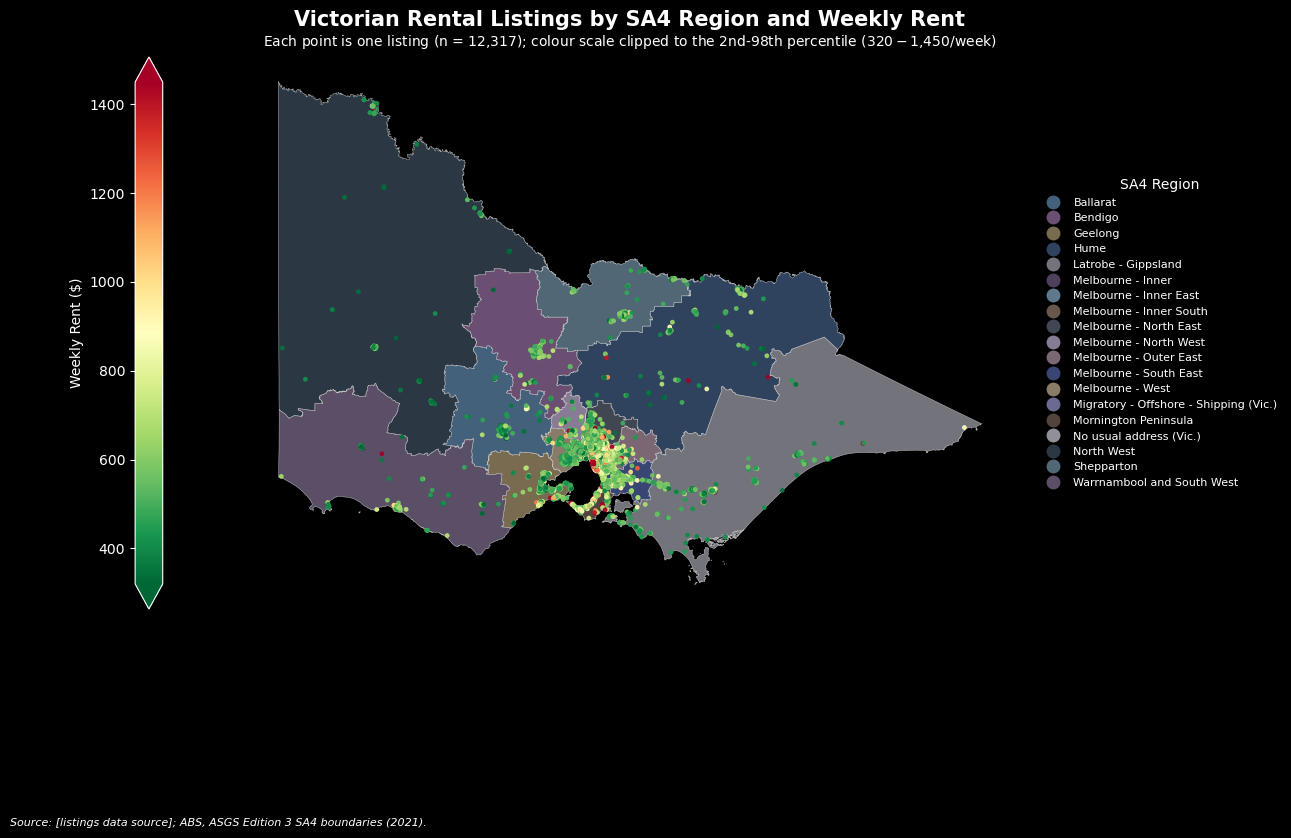

In [ ]:
from matplotlib.colors import ListedColormap

# Convert Spark listings to Pandas
listings_pd = df.select("lat", "lon", "suburb", "weekly_rent").toPandas()

# Build GeoDataFrame from lat/lon points
listings_gdf = gpd.GeoDataFrame(
    listings_pd,
    geometry=gpd.points_from_xy(listings_pd["lon"], listings_pd["lat"]),
    crs="EPSG:4326"
)

# Load SA4 shapefile, filter to Victoria
sa4 = gpd.read_file(SHP_PATH)
sa4_vic = sa4[sa4["STE_NAME21"] == "Victoria"]

# Match CRS
listings_gdf = listings_gdf.to_crs(sa4_vic.crs)

# Outlier-resistant colour scale for rent
vmin, vmax = np.percentile(listings_gdf["weekly_rent"], [2, 98])

# Muted region palette (blues, purples, taupes, greys; no red/green hues).
# 20 colours because Victoria has more SA4 zones than the Melbourne subset;
# consecutive colours alternate in hue and lightness so neighbours differ.
region_palette = [
    "#5b82a6",  # steel blue
    "#8e6b99",  # dusty purple
    "#a3906c",  # khaki
    "#3f5a80",  # navy slate
    "#9a9aa6",  # light grey
    "#6a5580",  # plum
    "#7fa3bd",  # light steel blue
    "#8a7568",  # warm taupe
    "#56606e",  # charcoal blue
    "#b7a5c8",  # lavender
    "#a58a9c",  # rose grey
    "#4d5d99",  # indigo
    "#b8a58a",  # sand
    "#8f8fc4",  # periwinkle
    "#6e5a52",  # dark taupe
    "#c2c2cc",  # pale grey
    "#3a4a5a",  # dark slate
    "#6d8b9e",  # blue grey
    "#7a6a8a",  # muted violet
    "#9c8f7a",  # stone
]
region_cmap = ListedColormap(
    [region_palette[i % len(region_palette)] for i in range(len(sa4_vic))]
)

fig, ax = plt.subplots(figsize=(13, 10))

# --- Black background ---
fig.patch.set_facecolor("black")
ax.set_facecolor("black")

# --- Layer 1: SA4 zones, muted tints, legend on the right ---
sa4_vic.plot(
    ax=ax,
    column="SA4_NAME21",
    categorical=True,
    cmap=region_cmap,
    edgecolor="#d0d0d0",     # light borders so zone outlines show on black
    linewidth=0.4,
    alpha=0.75,
    legend=True,
    legend_kwds={
        "loc": "center left",
        "bbox_to_anchor": (1.02, 0.5),
        "fontsize": 8,
        "title": "SA4 Region",
        "frameon": False,
    }
)

# --- Layer 2: listings, green (low rent) -> red (high rent), 
# colorbar on the left ---
listings_gdf.plot(
    ax=ax,
    column="weekly_rent",
    cmap="RdYlGn_r",         # reversed so green = low, red = high
    markersize=6,
    alpha=0.9,
    vmin=vmin,
    vmax=vmax,
    legend=True,
    legend_kwds={
        "location": "left",
        "shrink": 0.6,
        "label": "Weekly Rent ($)",
        "extend": "both",
        "pad": 0.08,
    }
)

# --- Title + subtitle, both anchored to the map axes ---
ax.set_title(
    "Victorian Rental Listings by SA4 Region and Weekly Rent",
    fontsize=15, fontweight="bold", pad=22, color="white"
)
ax.text(
    0.5, 1.01,
    f"Each point is one listing (n = {len(listings_gdf):,}); "
    f"colour scale clipped to the 2nd-98th percentile\
          (${vmin:,.0f}-${vmax:,.0f}/week)",
    transform=ax.transAxes, ha="center", va="bottom",
    fontsize=10, color="white"
)

# --- Caption (bottom-left of the figure) ---
fig.text(
    0.01, 0.01,
    "Source: [listings data source]; ABS, ASGS Edition 3 SA4 boundaries \
        (2021).",
    ha="left", va="bottom", fontsize=8, color="white", style="italic"
)

# --- White text for the right-hand region legend ---
region_legend = ax.get_legend()
region_legend.get_title().set_color("white")
for text in region_legend.get_texts():
    text.set_color("white")

# --- White text/ticks/outline for the left-hand rent colorbar ---
for cb_ax in [a for a in fig.axes if a is not ax]:
    cb_ax.tick_params(colors="white", which="both")
    cb_ax.xaxis.label.set_color("white")
    cb_ax.yaxis.label.set_color("white")
    cb_ax.set_facecolor("black")
    for spine in cb_ax.spines.values():
        spine.set_edgecolor("white")

ax.set_axis_off()
plt.tight_layout(rect=[0, 0.03, 1, 0.98])  # leave room for the caption

# Save AFTER everything is drawn so the file matches the on-screen figure
plt.savefig(
    "../Figures/melbourne_sa4_rent_map_full.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="black"        # keep the black background in the saved file
)
plt.show()

Found 8 zones:
['Melbourne - Inner', 'Melbourne - Inner East', 'Melbourne - Inner South', 'Melbourne - North East', 'Melbourne - North West', 'Melbourne - Outer East', 'Melbourne - South East', 'Melbourne - West']


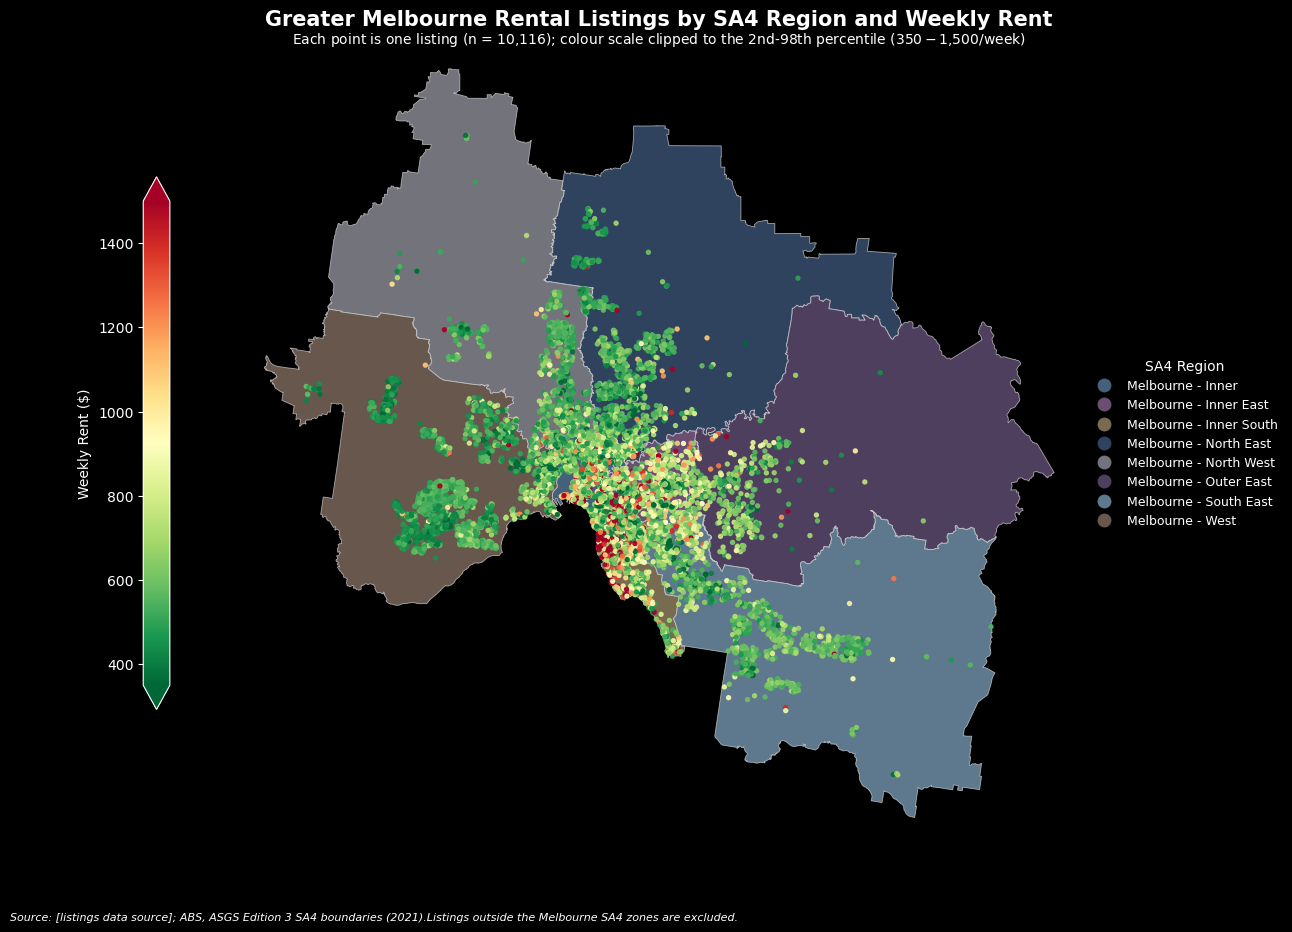

In [ ]:
# Filter to SA4 zones with "Melbourne" in the name
sa4_melb = sa4[sa4["SA4_NAME21"].str.contains("Melbourne", 
                                              case=False, na=False)]

print(f"Found {len(sa4_melb)} zones:")
print(sa4_melb["SA4_NAME21"].tolist())

# Match CRS
listings_gdf = listings_gdf.to_crs(sa4_melb.crs)

# Clip listings to just those inside the Melbourne SA4 zones
listings_melb = gpd.sjoin(listings_gdf, sa4_melb[["SA4_NAME21", "geometry"]], 
                          how="inner", predicate="within")

# Outlier-resistant colour scale for rent 
# (computed on the Melbourne subset only)
vmin, vmax = np.percentile(listings_melb["weekly_rent"], [2, 98])

# Muted region palette (blues, purples, taupes, greys; no red/green hues).
# Slightly lighter than before because colours blend with black at alpha < 1.
region_palette = [
    "#5b82a6",  # steel blue
    "#8e6b99",  # dusty purple
    "#a3906c",  # khaki
    "#3f5a80",  # navy slate
    "#9a9aa6",  # light grey
    "#6a5580",  # plum
    "#7fa3bd",  # light steel blue
    "#8a7568",  # warm taupe
    "#56606e",  # charcoal blue
    "#b7a5c8",  # lavender
]
region_cmap = ListedColormap(
    [region_palette[i % len(region_palette)] for i in range(len(sa4_melb))]
)

fig, ax = plt.subplots(figsize=(13, 10))

# --- Black background ---
fig.patch.set_facecolor("black")
ax.set_facecolor("black")

# --- Layer 1: SA4 zones, muted tints, legend on the right ---
sa4_melb.plot(
    ax=ax,
    column="SA4_NAME21",
    categorical=True,
    cmap=region_cmap,
    edgecolor="#d0d0d0",     # light borders so zone outlines show on black
    linewidth=0.6,
    alpha=0.75,
    legend=True,
    legend_kwds={
        "loc": "center left",
        "bbox_to_anchor": (1.02, 0.5),
        "fontsize": 9,
        "title": "SA4 Region",
        "frameon": False,
    }
)

# --- Layer 2: listings, green (low rent) -> red (high rent), 
# colorbar on the left ---
listings_melb.plot(
    ax=ax,
    column="weekly_rent",
    cmap="RdYlGn_r",         # reversed so green = low, red = high
    markersize=8,
    alpha=0.9,
    vmin=vmin,
    vmax=vmax,
    legend=True,
    legend_kwds={
        "location": "left",
        "shrink": 0.6,
        "label": "Weekly Rent ($)",
        "extend": "both",
        "pad": 0.08,
    }
)

# Zoom the plot to the Melbourne zones' extent (with a small buffer)
minx, miny, maxx, maxy = sa4_melb.total_bounds
buffer = 0.02
ax.set_xlim(minx - buffer, maxx + buffer)
ax.set_ylim(miny - buffer, maxy + buffer)

# --- Title + subtitle, both anchored to the map axes ---
ax.set_title(
    "Greater Melbourne Rental Listings by SA4 Region and Weekly Rent",
    fontsize=15, fontweight="bold", pad=22, color="white"
)
ax.text(
    0.5, 1.01,
    f"Each point is one listing (n = {len(listings_melb):,}); "
    f"colour scale clipped to the 2nd-98th percentile \
        (${vmin:,.0f}-${vmax:,.0f}/week)",
    transform=ax.transAxes, ha="center", va="bottom",
    fontsize=10, color="white"
)

# --- Caption (bottom-left of the figure) ---
fig.text(
    0.01, 0.01,
    "Source: [listings data source]; ABS, ASGS Edition 3 SA4 boundaries (2021)."
    "Listings outside the Melbourne SA4 zones are excluded.",
    ha="left", va="bottom", fontsize=8, color="white", style="italic"
)

# --- White text for the right-hand region legend ---
region_legend = ax.get_legend()
region_legend.get_title().set_color("white")
for text in region_legend.get_texts():
    text.set_color("white")

# --- White text/ticks/outline for the left-hand rent colorbar ---
for cb_ax in [a for a in fig.axes if a is not ax]:
    cb_ax.tick_params(colors="white", which="both")
    cb_ax.xaxis.label.set_color("white")
    cb_ax.yaxis.label.set_color("white")
    cb_ax.set_facecolor("black")
    for spine in cb_ax.spines.values():
        spine.set_edgecolor("white")

ax.set_axis_off()
plt.tight_layout(rect=[0, 0.03, 1, 0.98])  # leave room for the caption

# Save AFTER everything is drawn so the file matches the on-screen figure
plt.savefig(
    "../Figures/melbourne_sa4_rent_map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="black"        # keep the black background in the saved file
)
plt.show()